# Block 0 – Imports & Configuration


In [1]:
# Data manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt

# Metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Utilities
from pathlib import Path


# Block 1 Objective

The goal of this notebook is to establish **baseline forecasting models**
for the Store Item Demand Forecasting dataset.

These baselines will serve as reference points to evaluate whether
more complex models (machine learning or deep learning)
actually provide meaningful improvements.

Specifically, we will:
- Load the processed dataset with engineered features
- Define a proper time-based train / validation split
- Implement simple baseline models
- Evaluate them using standard regression metrics


# Block 2 – Load Processed Dataset

In [2]:
DATA_PATH = Path("../data/processed/demand_features.pkl")

df = pd.read_pickle(DATA_PATH)

df.head()


,date,store,item,sales,lag_1,lag_7,lag_14,lag_28,rolling_mean_7,rolling_std_7,rolling_mean_14,rolling_std_14,rolling_mean_28,rolling_std_28,day_of_week,week_of_year,month,year
0,2013-01-01,1,1,13,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,1,1,2013
1,2013-01-02,1,1,11,13.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,1,1,2013
2,2013-01-03,1,1,14,11.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3,1,1,2013
3,2013-01-04,1,1,13,14.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4,1,1,2013
4,2013-01-05,1,1,10,13.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5,1,1,2013


## 3.2 Fast check of the dataset

In [3]:
df.info()
df.isna().sum().sort_values(ascending=False).head()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 913000 entries, 0 to 912999
Data columns (total 18 columns):
 #   Column           Non-Null Count   Dtype         
---  ------           --------------   -----         
 0   date             913000 non-null  datetime64[ns]
 1   store            913000 non-null  int64         
 2   item             913000 non-null  int64         
 3   sales            913000 non-null  int64         
 4   lag_1            912500 non-null  float64       
 5   lag_7            909500 non-null  float64       
 6   lag_14           906000 non-null  float64       
 7   lag_28           899000 non-null  float64       
 8   rolling_mean_7   909500 non-null  float64       
 9   rolling_std_7    909500 non-null  float64       
 10  rolling_mean_14  906000 non-null  float64       
 11  rolling_std_14   906000 non-null  float64       
 12  rolling_mean_28  899000 non-null  float64       
 13  rolling_std_28   899000 non-null  float64       
 14  day_of_week      913

rolling_std_28     14000
lag_28             14000
rolling_mean_28    14000
rolling_std_14      7000
rolling_mean_14     7000
dtype: int64

# Block 3 – Train / Validation Split (Time-based)

## 3.1 Sort by time (defensive programming)

In [4]:
df = df.sort_values("date")

## 3.2 Define cutoff date

Using last date as validation

In [5]:
cutoff_date = df["date"].max() - pd.DateOffset(months=12)

train_df = df[df["date"] <= cutoff_date]
val_df   = df[df["date"] > cutoff_date]

print(train_df.shape, val_df.shape)


(730500, 18) (182500, 18)


## 3.3 Define target

In [6]:
TARGET = "sales"

y_train = train_df[TARGET]
y_val   = val_df[TARGET]


# Block 4 – Naive Baseline (Last Value)

This baseline assumes that the best prediction for tomorrow is yesterday's value. It's the simplest possible model, yet surprisingly strong in time series analysis.

## 4.1 Prediction

In [7]:
y_pred_naive = val_df["lag_1"]


## 4.2 Evaluation

In [8]:
mae_naive = mean_absolute_error(y_val, y_pred_naive)
mse_naive = mean_squared_error(y_val, y_pred_naive)
rmse_naive = np.sqrt(mse_naive)

print(f"Naive MAE: {mae_naive:.2f}")
print(f"Naive RMSE: {rmse_naive:.2f}")



Naive MAE: 11.24
Naive RMSE: 15.39


# Block 5 – Seasonal Naive Baseline (Lag 7)
This baseline assumes that demand follows a weekly pattern

## 5.1 Prediction

In [9]:
y_pred_seasonal = val_df["lag_7"]

## 5.2 Evaluation 

In [10]:
mae_seasonal = mean_absolute_error(y_val, y_pred_seasonal)
rmse_seasonal = np.sqrt(mean_squared_error(y_val, y_pred_seasonal))

print(f"Seasonal Naive MAE: {mae_seasonal:.2f}")
print(f"Seasonal Naive RMSE: {rmse_seasonal:.2f}")

Seasonal Naive MAE: 8.84
Seasonal Naive RMSE: 11.60


# Block 6 – Rolling Mean Baseline

This baseline smooths out noise using the moving average of the last few days.
It is useful when the series has high daily variability.


## 6.1 Prediction

In [11]:
y_pred_rolling = val_df["rolling_mean_7"]


## 6.2 Evaluation

In [12]:
mae_rolling = mean_absolute_error(y_val, y_pred_rolling)
rmse_rolling = np.sqrt(mean_squared_error(y_val, y_pred_rolling))

print(f"Rolling Mean MAE: {mae_rolling:.2f}")
print(f"Rolling Mean RMSE: {rmse_rolling:.2f}")


Rolling Mean MAE: 8.98
Rolling Mean RMSE: 11.86


# Block 7 – Baseline Comparison

## 7.1 Comparison Between Metrics

In [13]:
baseline_results = pd.DataFrame({
    "Model": ["Naive", "Seasonal Naive (Lag 7)", "Rolling Mean (7d)"],
    "MAE": [mae_naive, mae_seasonal, mae_rolling],
    "RMSE": [rmse_naive, rmse_seasonal, rmse_rolling]
})

baseline_results


,Model,MAE,RMSE
0,Naive,11.244734,15.389245
1,Seasonal Naive (Lag 7),8.841452,11.596704
2,Rolling Mean (7d),8.979609,11.859588


## 7.2 Visualization

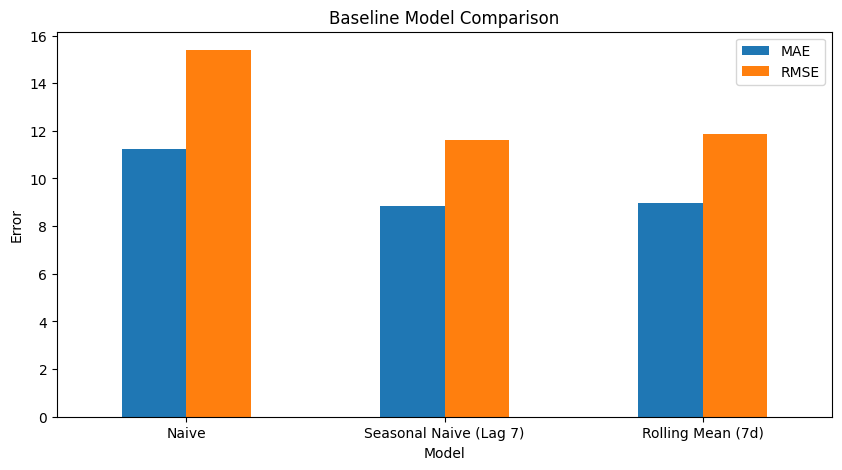

In [14]:
baseline_results.set_index("Model")[["MAE", "RMSE"]].plot(
    kind="bar",
    figsize=(10,5)
)

plt.title("Baseline Model Comparison")
plt.ylabel("Error")
plt.xticks(rotation=0)
plt.show()


# Block 8 – Conclusions

In this notebook, we established several baseline forecasting models
to evaluate demand prediction performance.

Key takeaways:
- The naive baseline provides a strong lower bound and should never be ignored.
- The seasonal naive model improves performance by capturing weekly patterns.
- Rolling mean smoothing further reduces noise and can outperform simpler baselines.

These results provide a solid reference point to assess whether
more advanced models (machine learning or deep learning)
deliver meaningful improvements over simple heuristics.

In the next notebook, we will build machine learning models
and compare them against these baselines.

Any model must outperform a strong seasonal naive baseline (lag 7), which already captures weekly seasonality.

# Block 9 – Clean and Save dataset

In [15]:
df_model = df.dropna().reset_index(drop=True)

df_model.shape


(899000, 18)

In [16]:
df_model.to_pickle("../data/processed/demand_forecasting_features.pkl")
